# SwinIR — Optimized SEMICON 2× Super-Resolution Benchmark

This Kaggle notebook trains the existing compact SwinIR body on the manifest-defined **SEMICON_SR_2X_v2** protocol: grayscale LR **512×384** to HR **1024×768**. It never creates a new split.

## Optimization decisions

- The SwinIR body remains **60 channels, 8 shifted-window blocks, 6 heads, window size 8**.
- Training is reduced from 300 to **100 epochs**.
- Each epoch samples **1,024 aligned LR/HR patches** from the full training set. Over 100 epochs this supplies 102,400 randomized patches while avoiding 291,000 source decodes.
- AMP and an effective batch of 8 improve T4 throughput.
- A fixed, split-spanning **64-image validation subset** runs every 5 epochs.
- Validation uses 256-pixel LR tiles with 32-pixel overlap, reducing the typical tile count from nine to six.
- Heavy NIQE, BRISQUE, PIQE, and FSIM models are loaded only after final reference-metric testing.

Estimated Kaggle T4 budget: **9–14 GB VRAM**, approximately **7–12 minutes per training epoch**, and **12–20 hours for 100 epochs including periodic validation**. Final full-test IQA may add 1–3 hours. Runtime varies by Kaggle storage and GPU allocation; `last_checkpoint.pth` supports continuation across sessions.


## 1. Environment and reproducibility

In [1]:
from __future__ import annotations
import gc, json, math, os, random, subprocess, sys, time
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, RandomSampler, Subset

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=True
torch.backends.cuda.matmul.allow_tf32=True
torch.set_float32_matmul_precision("high")
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP=DEVICE.type=="cuda"
print("PyTorch:",torch.__version__,"| device:",DEVICE)
if AMP:
 print(torch.cuda.get_device_name(0),"|",round(torch.cuda.get_device_properties(0).total_memory/2**30,1),"GiB")


PyTorch: 2.10.0+cu128 | device: cuda
Tesla T4 | 14.6 GiB


## 2. Revised hyperparameters

| Setting | Revised value | Previous value |
|---|---:|---:|
| Epoch target | 100 | 300 |
| LR patch | 96×96 | 96×96 |
| HR target patch | 192×192 | 192×192 |
| Batch size | 8 | 4 |
| Samples per epoch | 1,024 randomized patches | 2,910 images |
| Optimizer | AdamW | AdamW |
| Initial LR | 2×10⁻⁴ | 2×10⁻⁴ |
| Scheduler | CosineAnnealingLR | CosineAnnealingLR |
| Validation frequency | Every 5 epochs | Every epoch |
| Training validation set | Fixed 64-image subset | All 831 images |
| Final test set | All 417 images | All 417 images |
| Inference tile | 256, overlap 32 | 192, overlap 32 |
| Loss | L1 | L1 + gradient term |
| Best checkpoint | Validation PSNR | Validation PSNR |
| Early stopping | 10 validation checks | 60 epochs |

The fixed validation subset is for efficient model selection only. The best checkpoint is evaluated on the complete untouched test split. No NIQE/BRISQUE/PIQE/FSIM calculation occurs during training or validation.


In [2]:
MODEL_NAME="SwinIR_SEMICON_Optimized"
EPOCHS=100
CROP_SIZE=96
BATCH_SIZE=8
TRAIN_SAMPLES_PER_EPOCH=1024
LR=2e-4
WEIGHT_DECAY=1e-4
WORKERS=2
VALIDATE_EVERY=5
VAL_SAMPLES=64
TILE=256
OVERLAP=32
PATIENCE_CHECKS=10
MIN_DELTA=0.005
RESUME=True
print(dict(epochs=EPOCHS,crop=CROP_SIZE,batch=BATCH_SIZE,samples_per_epoch=TRAIN_SAMPLES_PER_EPOCH,
           lr=LR,validate_every=VALIDATE_EVERY,val_samples=VAL_SAMPLES,tile=TILE))


{'epochs': 100, 'crop': 96, 'batch': 8, 'samples_per_epoch': 1024, 'lr': 0.0002, 'validate_every': 5, 'val_samples': 64, 'tile': 256}


## 3. Manifest-defined dataset and paired loaders

Training uses paired random crops with aligned flips and rotations. Validation and test use the original images and manifest identities without augmentation. No image is reassigned to another split.

In [3]:
INPUT_ROOT=Path("/kaggle/input")
RUN_ROOT=Path("/kaggle/working")/MODEL_NAME
RUN_ROOT.mkdir(parents=True,exist_ok=True)

def records_from(payload):
    if isinstance(payload,list): return payload
    if isinstance(payload,dict) and isinstance(payload.get("samples"),list): return payload["samples"]
    raise ValueError("Unsupported manifest schema")

def locate_dataset():
    candidates=[]
    for p in INPUT_ROOT.rglob("manifest.json"):
        try:
            payload=json.loads(p.read_text(encoding="utf-8")); rows=records_from(payload)
            splits=Counter(str(r.get("split","")).lower() for r in rows)
            label=(p.as_posix()+str(payload.get("dataset","") if isinstance(payload,dict) else "")).lower()
            score=100*int("sr_2x" in label or "sr-2x" in label)+20*int("noise" not in label)+len(rows)/10000
            if all(splits[s]>0 for s in ("train","val","test")): candidates.append((score,p,payload,rows))
        except Exception: pass
    if not candidates: raise FileNotFoundError("SEMICON_SR_2X_v2 manifest not found under /kaggle/input")
    _,p,payload,rows=max(candidates,key=lambda x:x[0]); return p.parent,p,payload,rows

ROOT,MANIFEST,PAYLOAD,RECORDS=locate_dataset()
def norm_split(value):
    value=str(value).lower(); return "val" if value in {"validation","valid"} else value
SPLITS={s:[r for r in RECORDS if norm_split(r.get("split"))==s] for s in ("train","val","test")}
print("Dataset:",ROOT,"| manifest:",MANIFEST); print("Splits:",{k:len(v) for k,v in SPLITS.items()})
assert all(SPLITS.values())

def resolve(value):
    p=Path(str(value))
    if p.is_absolute() and p.is_file(): return p
    if (ROOT/p).is_file(): return ROOT/p
    hits=list(ROOT.rglob(p.name))
    if len(hits)==1:return hits[0]
    raise FileNotFoundError(value)

def pair_paths(record):
    return resolve(record.get("lr_path") or record.get("LR path")),resolve(record.get("hr_path") or record.get("HR path"))

class PairedSRDataset(Dataset):
    def __init__(self,rows,training=False): self.rows=rows; self.training=training
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        record=self.rows[index]; lr_path,hr_path=pair_paths(record)
        with Image.open(lr_path) as image: lr=np.asarray(image.convert("L"),dtype=np.float32)/255.
        with Image.open(hr_path) as image: hr=np.asarray(image.convert("L"),dtype=np.float32)/255.
        if hr.shape!=(lr.shape[0]*2,lr.shape[1]*2): raise ValueError(f"Invalid 2× pair: {lr_path} {lr.shape}, {hr_path} {hr.shape}")
        if self.training:
            c=min(CROP_SIZE,*lr.shape); y=np.random.randint(0,lr.shape[0]-c+1); x=np.random.randint(0,lr.shape[1]-c+1)
            lr=lr[y:y+c,x:x+c]; hr=hr[2*y:2*(y+c),2*x:2*(x+c)]
            if np.random.random()<.5: lr=np.fliplr(lr); hr=np.fliplr(hr)
            if np.random.random()<.5: lr=np.flipud(lr); hr=np.flipud(hr)
            k=np.random.randint(0,4); lr=np.rot90(lr,k); hr=np.rot90(hr,k)
        return {"lr":torch.from_numpy(np.ascontiguousarray(lr))[None],"hr":torch.from_numpy(np.ascontiguousarray(hr))[None],"id":str(record.get("sample_id",index))}

def worker_seed(worker_id):
    seed=(torch.initial_seed()+worker_id)%2**32; random.seed(seed); np.random.seed(seed)

generator=torch.Generator().manual_seed(SEED)
train_ds=PairedSRDataset(SPLITS["train"],True)
train_sampler=RandomSampler(train_ds,replacement=True,num_samples=TRAIN_SAMPLES_PER_EPOCH,generator=generator)
val_full=PairedSRDataset(SPLITS["val"])
val_indices=np.linspace(0,len(val_full)-1,min(VAL_SAMPLES,len(val_full)),dtype=int).tolist()
val_ds=Subset(val_full,val_indices)
test_ds=PairedSRDataset(SPLITS["test"])
common=dict(num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0,prefetch_factor=2 if WORKERS else None)
# Remove a None prefetch value because PyTorch disallows it with some versions.
common={k:v for k,v in common.items() if v is not None}
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,sampler=train_sampler,drop_last=True,worker_init_fn=worker_seed,**common)
val_loader=DataLoader(val_ds,batch_size=1,shuffle=False,**common)
test_loader=DataLoader(test_ds,batch_size=1,shuffle=False,**common)
batch=next(iter(train_loader)); print("Training LR/HR:",batch["lr"].shape,batch["hr"].shape,"| steps/epoch:",len(train_loader),"| validation subset:",len(val_ds))


Dataset: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2 | manifest: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2/manifest.json
Splits: {'train': 2910, 'val': 831, 'test': 417}
Training LR/HR: torch.Size([8, 1, 96, 96]) torch.Size([8, 1, 192, 192]) | steps/epoch: 128 | validation subset: 64


## 4. Architecture implementation

The following cell contains the complete model definition used by this notebook. It is deliberately local to the notebook so checkpoint reconstruction does not depend on a cloned repository.

In [4]:
class ResBlock(nn.Module):
 def __init__(self,c,scale=1.): super().__init__(); self.body=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.ReLU(True),nn.Conv2d(c,c,3,1,1)); self.scale=scale
 def forward(self,x): return x+self.body(x)*self.scale
class CALayer(nn.Module):
 def __init__(self,c,r=8): super().__init__(); self.m=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(c,max(4,c//r),1),nn.ReLU(True),nn.Conv2d(max(4,c//r),c,1),nn.Sigmoid())
 def forward(self,x): return x*self.m(x)
class CAB(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.GELU(),nn.Conv2d(c,c,3,1,1),CALayer(c))
 def forward(self,x): return x+self.m(x)
class LayerNorm2d(nn.Module):
 def __init__(self,c): super().__init__(); self.w=nn.Parameter(torch.ones(1,c,1,1)); self.b=nn.Parameter(torch.zeros(1,c,1,1))
 def forward(self,x):
  v=x.var(1,keepdim=True,unbiased=False); m=x.mean(1,keepdim=True); return (x-m)/torch.sqrt(v+1e-5)*self.w+self.b

def window_partition(x,ws):
 b,c,h,w=x.shape; return x.view(b,c,h//ws,ws,w//ws,ws).permute(0,2,4,3,5,1).reshape(-1,ws*ws,c)
def window_reverse(z,ws,h,w,b): return z.view(b,h//ws,w//ws,ws,ws,-1).permute(0,5,1,3,2,4).reshape(b,-1,h,w)
class WinBlock(nn.Module):
 def __init__(self,c,heads=6,ws=8,shift=0,channel=False): super().__init__(); self.n1=LayerNorm2d(c); self.att=nn.MultiheadAttention(c,heads,batch_first=True); self.n2=LayerNorm2d(c); self.ff=nn.Sequential(nn.Conv2d(c,4*c,1),nn.GELU(),nn.Conv2d(4*c,c,1)); self.ws=ws; self.shift=shift; self.ca=CALayer(c) if channel else nn.Identity()
 def forward(self,x):
  b,c,h,w=x.shape; padh=(-h)%self.ws; padw=(-w)%self.ws; y=F.pad(self.n1(x),(0,padw,0,padh),mode="reflect"); hp,wp=y.shape[-2:]
  if self.shift:y=torch.roll(y,(-self.shift,-self.shift),(-2,-1))
  z=window_partition(y,self.ws); z=self.att(z,z,z,need_weights=False)[0]; y=window_reverse(z,self.ws,hp,wp,b)
  if self.shift:y=torch.roll(y,(self.shift,self.shift),(-2,-1))
  x=x+self.ca(y[:,:,:h,:w]); return x+self.ff(self.n2(x))
class Model(nn.Module):
 def __init__(self,c=60,n=8): super().__init__(); self.h=nn.Conv2d(1,c,3,1,1); self.b=nn.Sequential(*[WinBlock(c,6,8,0 if i%2==0 else 4) for i in range(n)]); self.t=nn.Conv2d(c,c,3,1,1); self.up=nn.Sequential(nn.Conv2d(c,4*c,3,1,1),nn.PixelShuffle(2),nn.Conv2d(c,1,3,1,1))
 def forward(self,x): h=self.h(x); return self.up(h+self.t(self.b(h)))

## 5. Efficient training and periodic validation

Training uses AMP, channels-last tensors, gradient clipping, AdamW, and cosine decay. Validation runs only every fifth epoch on a deterministic 64-image subset. No predictions or IQA networks are retained during validation.

`last_checkpoint.pth` is updated every epoch and contains the model, optimizer, scheduler, scaler, random states, and history. `best_checkpoint.pth` is updated only when periodic validation PSNR improves.


In [5]:
model=Model(c=60,n=8).to(DEVICE).to(memory_format=torch.channels_last)
parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters:",f"{parameters:,}")
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,betas=(.9,.99),weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=LR*.01)
scaler=torch.amp.GradScaler("cuda",enabled=AMP)

def metric_batch(pred,target):
    pred=pred.float().clamp(0,1); target=target.float()
    mse=((pred-target)**2).flatten(1).mean(1); mae=(pred-target).abs().flatten(1).mean(1)
    psnr=-10*torch.log10(mse.clamp_min(1e-12))
    mu_p=F.avg_pool2d(pred,11,1,5); mu_t=F.avg_pool2d(target,11,1,5)
    var_p=F.avg_pool2d(pred*pred,11,1,5)-mu_p.square(); var_t=F.avg_pool2d(target*target,11,1,5)-mu_t.square()
    covariance=F.avg_pool2d(pred*target,11,1,5)-mu_p*mu_t
    ssim=((2*mu_p*mu_t+.01**2)*(2*covariance+.03**2)/((mu_p.square()+mu_t.square()+.01**2)*(var_p+var_t+.03**2))).flatten(1).mean(1)
    return psnr.mean().item(),ssim.mean().item(),mae.mean().item(),mse.mean().item()

@torch.inference_mode()
def tiled_forward(x,tile=TILE,overlap=OVERLAP):
    scale=2; b,_,h,w=x.shape
    if h<=tile and w<=tile:return model(x)
    output=torch.zeros((b,1,h*scale,w*scale),device=x.device); weight=torch.zeros_like(output); step=tile-overlap
    ys=list(range(0,max(1,h-tile+1),step)); xs=list(range(0,max(1,w-tile+1),step))
    if not ys or ys[-1]!=max(0,h-tile):ys.append(max(0,h-tile))
    if not xs or xs[-1]!=max(0,w-tile):xs.append(max(0,w-tile))
    for y in ys:
        for x0 in xs:
            patch=x[:,:,y:y+tile,x0:x0+tile].contiguous(memory_format=torch.channels_last)
            prediction=model(patch)
            ph,pw=prediction.shape[-2:]; oy,ox=y*scale,x0*scale
            output[:,:,oy:oy+ph,ox:ox+pw]+=prediction.float(); weight[:,:,oy:oy+ph,ox:ox+pw]+=1
    return output/weight.clamp_min(1)

@torch.inference_mode()
def validate():
    model.eval(); totals=np.zeros(5,dtype=np.float64); count=0
    for batch in tqdm(val_loader,desc="validation subset",leave=False):
        lr=batch["lr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        hr=batch["hr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        with torch.amp.autocast("cuda",enabled=AMP): prediction=tiled_forward(lr).clamp(0,1); loss=F.l1_loss(prediction,hr)
        psnr,ssim,mae,mse=metric_batch(prediction,hr); totals+=np.array([loss.item(),psnr,ssim,mae,mse]); count+=1
    return dict(zip(["val_loss","psnr","ssim","mae","mse"],totals/max(1,count)))

best_psnr=-float("inf"); checks_without_gain=0; history=[]; start_epoch=1
last_path=RUN_ROOT/"last_checkpoint.pth"; best_path=RUN_ROOT/"best_checkpoint.pth"
if RESUME and last_path.is_file():
    checkpoint=torch.load(last_path,map_location=DEVICE,weights_only=False)
    model.load_state_dict(checkpoint["model"]); optimizer.load_state_dict(checkpoint["optimizer"]); scheduler.load_state_dict(checkpoint["scheduler"]); scaler.load_state_dict(checkpoint["scaler"])
    history=checkpoint["history"]; best_psnr=checkpoint["best_psnr"]; checks_without_gain=checkpoint["checks_without_gain"]; start_epoch=checkpoint["epoch"]+1
    if "python_rng" in checkpoint: random.setstate(checkpoint["python_rng"])
    if "numpy_rng" in checkpoint: np.random.set_state(checkpoint["numpy_rng"])
    if "torch_rng" in checkpoint: torch.set_rng_state(checkpoint["torch_rng"])
    if "sampler_rng" in checkpoint: generator.set_state(checkpoint["sampler_rng"])
    if AMP and "cuda_rng" in checkpoint: torch.cuda.set_rng_state_all(checkpoint["cuda_rng"])
    print("Resumed at epoch",start_epoch)

for epoch in range(start_epoch,EPOCHS+1):
    started=time.perf_counter(); model.train(); total_loss=0.; seen=0
    if AMP: torch.cuda.reset_peak_memory_stats()
    bar=tqdm(train_loader,desc=f"SwinIR {epoch:03d}/{EPOCHS}")
    for batch in bar:
        lr=batch["lr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        hr=batch["hr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda",enabled=AMP): prediction=model(lr); loss=F.l1_loss(prediction,hr)
        scaler.scale(loss).backward(); scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update()
        total_loss+=loss.item()*lr.size(0); seen+=lr.size(0); bar.set_postfix(loss=f"{total_loss/seen:.5f}")
    scheduler.step()
    do_validation=epoch%VALIDATE_EVERY==0 or epoch==EPOCHS
    metrics=validate() if do_validation else {"val_loss":np.nan,"psnr":np.nan,"ssim":np.nan,"mae":np.nan,"mse":np.nan}
    row={"epoch":epoch,"train_loss":total_loss/max(1,seen),"lr":optimizer.param_groups[0]["lr"],"epoch_minutes":(time.perf_counter()-started)/60,**metrics}
    history.append(row); pd.DataFrame(history).to_csv(RUN_ROOT/"training_history.csv",index=False)
    if do_validation:
        improved=metrics["psnr"]>best_psnr+MIN_DELTA
        if improved:
            best_psnr=metrics["psnr"]; checks_without_gain=0
            torch.save({"model":model.state_dict(),"epoch":epoch,"metrics":metrics,"config":{"channels":60,"blocks":8,"window":8}},best_path)
        else: checks_without_gain+=1
    state={"epoch":epoch,"model":model.state_dict(),"optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),"history":history,"best_psnr":best_psnr,"checks_without_gain":checks_without_gain,"python_rng":random.getstate(),"numpy_rng":np.random.get_state(),"torch_rng":torch.get_rng_state(),"sampler_rng":generator.get_state()}
    if AMP: state["cuda_rng"]=torch.cuda.get_rng_state_all()
    torch.save(state,last_path)
    peak=torch.cuda.max_memory_allocated()/2**30 if AMP else 0
    print(row,"| best PSNR",best_psnr,"| checks",checks_without_gain,"/",PATIENCE_CHECKS,"| peak GiB",round(peak,2))
    gc.collect()
    if AMP:torch.cuda.empty_cache()
    if do_validation and checks_without_gain>=PATIENCE_CHECKS:
        print("Early stopping after",checks_without_gain,"validation checks without improvement"); break


Trainable parameters: 515,281


SwinIR 001/100:   0%|          | 0/128 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.07071573736902792, 'lr': 0.00019995114947620745, 'epoch_minutes': 0.6773017300000002, 'val_loss': nan, 'psnr': nan, 'ssim': nan, 'mae': nan, 'mse': nan} | best PSNR -inf | checks 0 / 10 | peak GiB 3.02


SwinIR 002/100:   0%|          | 0/128 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.0426036324352026, 'lr': 0.00019980464611439892, 'epoch_minutes': 0.5795628472499998, 'val_loss': nan, 'psnr': nan, 'ssim': nan, 'mae': nan, 'mse': nan} | best PSNR -inf | checks 0 / 10 | peak GiB 2.76


...

SwinIR 099/100:   0%|          | 0/128 [00:00<?, ?it/s]

{'epoch': 99, 'train_loss': 0.03100636217277497, 'lr': 2.048850523792572e-06, 'epoch_minutes': 0.6318648235000031, 'val_loss': nan, 'psnr': nan, 'ssim': nan, 'mae': nan, 'mse': nan} | best PSNR 25.65719737112522 | checks 1 / 10 | peak GiB 2.76


SwinIR 100/100:   0%|          | 0/128 [00:00<?, ?it/s]

validation subset:   0%|          | 0/64 [00:00<?, ?it/s]

{'epoch': 100, 'train_loss': 0.03129003444337286, 'lr': 2.0000000000000003e-06, 'epoch_minutes': 1.387989515533324, 'val_loss': np.float64(0.035348118137335405), 'psnr': np.float64(25.655574217438698), 'ssim': np.float64(0.7154879998415709), 'mae': np.float64(0.035348118137335405), 'mse': np.float64(0.00393853472542105)} | best PSNR 25.65719737112522 | checks 2 / 10 | peak GiB 2.76


## 6. Complete final evaluation

Only `best_checkpoint.pth` is evaluated on all 417 manifest-defined test images. Reference metrics and inference timing are streamed first. Predictions are saved once so the four advanced IQA passes do not rerun SwinIR.

NIQE, BRISQUE, and PIQE are no-reference natural-image metrics; for SEM imagery they should be interpreted as secondary diagnostic signals. FSIM uses the clean HR reference. `pyiqa` is imported or installed only in this final section.


complete reference-metric test:   0%|          | 0/417 [00:00<?, ?it/s]

/tmp/ipykernel_23/3299114178.py:20: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  array=np.rint(prediction[0,0].float().cpu().numpy()*255).astype(np.uint8); Image.fromarray(array,mode="L").save(prediction_path)


Installing pyiqa for final-only NIQE, BRISQUE, PIQE, and FSIM...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 27.8 MB

100%|██████████| 8.15k/8.15k [00:00<00:00, 12.9MB/s]


niqe:   0%|          | 0/417 [00:00<?, ?it/s]

...

Computing piqe on the complete test split


piqe:   0%|          | 0/417 [00:00<?, ?it/s]

Computing fsim on the complete test split


fsim:   0%|          | 0/417 [00:00<?, ?it/s]

,model,checkpoint_epoch,parameters,inference_time_s,fps,peak_gpu_memory_gib,psnr,ssim,mae,mse,rmse,niqe,brisque,piqe,fsim,entropy
0,SwinIR,90,515281,0.700191,1.428181,0.381867,26.391615,0.740166,0.030153,0.003019,0.051113,7.266296,48.109889,27.007564,0.986873,6.278171


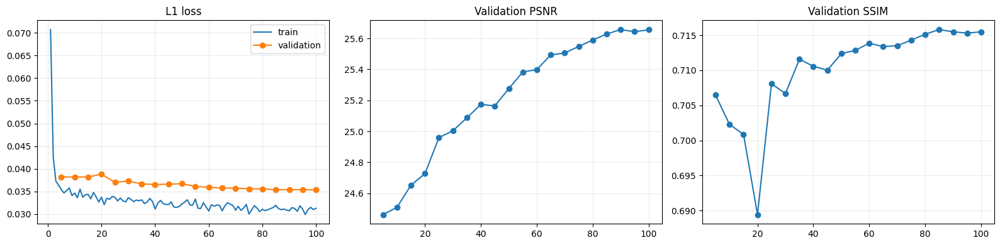

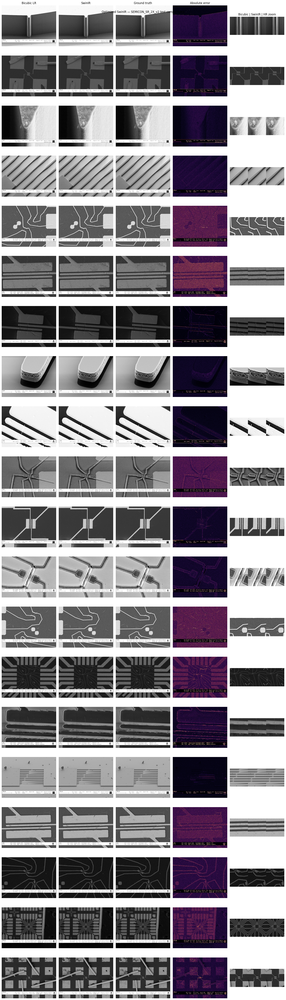

All outputs: /kaggle/working/SwinIR_SEMICON_Optimized


In [6]:
checkpoint=torch.load(best_path,map_location=DEVICE,weights_only=False); model.load_state_dict(checkpoint["model"]); model.eval()
PREDICTION_DIR=RUN_ROOT/"test_predictions"; PREDICTION_DIR.mkdir(exist_ok=True)

def entropy_score(tensor):
    array=(tensor.clamp(0,1)*255).byte().cpu().numpy().ravel(); histogram=np.bincount(array,minlength=256).astype(float); probability=histogram[histogram>0]/histogram.sum()
    return float(-(probability*np.log2(probability)).sum())

rows=[]; inference=[]
if AMP:torch.cuda.reset_peak_memory_stats()
with torch.inference_mode():
    for index,batch in enumerate(tqdm(test_loader,desc="complete reference-metric test")):
        lr=batch["lr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        hr=batch["hr"].to(DEVICE,non_blocking=True).contiguous(memory_format=torch.channels_last)
        if AMP:torch.cuda.synchronize()
        started=time.perf_counter()
        with torch.amp.autocast("cuda",enabled=AMP): prediction=tiled_forward(lr).clamp(0,1)
        if AMP:torch.cuda.synchronize()
        inference.append(time.perf_counter()-started); psnr,ssim,mae,mse=metric_batch(prediction,hr)
        prediction_path=PREDICTION_DIR/f"{index:06d}.png"
        array=np.rint(prediction[0,0].float().cpu().numpy()*255).astype(np.uint8); Image.fromarray(array,mode="L").save(prediction_path)
        rows.append({"sample_id":batch["id"][0],"prediction_path":str(prediction_path),"psnr":psnr,"ssim":ssim,"mae":mae,"mse":mse,"rmse":math.sqrt(mse),"entropy":entropy_score(prediction)})

per_image=pd.DataFrame(rows)
gc.collect()
if AMP:torch.cuda.empty_cache()

try:
    import pyiqa
except ImportError:
    print("Installing pyiqa for final-only NIQE, BRISQUE, PIQE, and FSIM...")
    subprocess.check_call([sys.executable,"-m","pip","install","-q","pyiqa"])
    import pyiqa

available=set(pyiqa.list_models()); required={"niqe":"niqe","brisque":"brisque","piqe":"piqe","fsim":"fsim"}
missing=[name for name in required.values() if name not in available]
if missing:raise RuntimeError(f"Installed pyiqa does not provide required metrics: {missing}")

def pil_tensor(path):
    with Image.open(path) as image: array=np.asarray(image.convert("L"),dtype=np.float32)/255.
    return torch.from_numpy(array)[None,None].repeat(1,3,1,1)

for column,metric_name in required.items():
    print("Computing",column,"on the complete test split")
    metric=pyiqa.create_metric(metric_name,device=DEVICE); values=[]
    with torch.inference_mode():
        for index,batch in enumerate(tqdm(test_loader,desc=column,leave=False)):
            prediction=pil_tensor(per_image.loc[index,"prediction_path"]).to(DEVICE)
            if column=="fsim":
                reference=batch["hr"].repeat(1,3,1,1).to(DEVICE); value=metric(prediction,reference)
            else:value=metric(prediction)
            values.append(float(value.mean()))
    per_image[column]=values; del metric; gc.collect()
    if AMP:torch.cuda.empty_cache()

per_image.to_csv(RUN_ROOT/"test_per_image_metrics.csv",index=False)
summary={"model":"SwinIR","checkpoint_epoch":checkpoint["epoch"],"parameters":parameters,"inference_time_s":float(np.mean(inference)),"fps":float(1/np.mean(inference)),"peak_gpu_memory_gib":float(torch.cuda.max_memory_allocated()/2**30) if AMP else 0.}
for column in ["psnr","ssim","mae","mse","rmse","niqe","brisque","piqe","fsim","entropy"]:summary[column]=float(per_image[column].mean())
pd.DataFrame([summary]).to_csv(RUN_ROOT/"results.csv",index=False); display(pd.DataFrame([summary]))

history_frame=pd.DataFrame(history); validated=history_frame.dropna(subset=["psnr"])
fig,axes=plt.subplots(1,3,figsize=(16,4)); axes[0].plot(history_frame.epoch,history_frame.train_loss,label="train"); axes[0].plot(validated.epoch,validated.val_loss,"o-",label="validation"); axes[0].legend(); axes[0].set_title("L1 loss"); axes[1].plot(validated.epoch,validated.psnr,"o-"); axes[1].set_title("Validation PSNR"); axes[2].plot(validated.epoch,validated.ssim,"o-"); axes[2].set_title("Validation SSIM"); [axis.grid(alpha=.25) for axis in axes]; fig.tight_layout(); fig.savefig(RUN_ROOT/"training_curves.png",dpi=180); plt.show()

@torch.inference_mode()
def visual_examples(count=20):
    picks=np.random.default_rng(SEED).choice(len(test_ds),min(count,len(test_ds)),replace=False); fig,axes=plt.subplots(len(picks),5,figsize=(17,3*len(picks)))
    for row,index in enumerate(picks):
        item=test_ds[int(index)]; lr=item["lr"][None]; gt=item["hr"][0].numpy(); prediction_index=int(index)
        with Image.open(per_image.loc[prediction_index,"prediction_path"]) as image: restored=np.asarray(image.convert("L"),dtype=np.float32)/255.
        up=F.interpolate(lr,size=gt.shape[-2:],mode="bicubic",align_corners=False)[0,0].numpy(); error=np.abs(restored-gt); y=(gt.shape[0]-256)//2; x=(gt.shape[1]-256)//2
        arrays=[up,restored,gt,error,np.concatenate([up[y:y+256,x:x+256],restored[y:y+256,x:x+256],gt[y:y+256,x:x+256]],axis=1)]; titles=["Bicubic LR","SwinIR","Ground truth","Absolute error","Bicubic | SwinIR | HR zoom"]
        for column,(array,title) in enumerate(zip(arrays,titles)):
            axes[row,column].imshow(array,cmap="inferno" if column==3 else "gray",vmin=0,vmax=.2 if column==3 else 1); axes[row,column].axis("off"); axes[row,column].set_title(title if row==0 else "")
    fig.suptitle("Optimized SwinIR — SEMICON_SR_2X_v2 test comparisons"); fig.tight_layout(); fig.savefig(RUN_ROOT/"test_visual_comparisons.png",dpi=140,bbox_inches="tight"); plt.show()
visual_examples()
print("All outputs:",RUN_ROOT)


## 7. Benchmark interpretation

The notebook exports:

- `best_checkpoint.pth` — highest periodic validation-subset PSNR;
- `last_checkpoint.pth` — complete resumable state;
- `training_history.csv` and `training_curves.png`;
- `results.csv` — aggregate complete-test benchmark;
- `test_per_image_metrics.csv` — all requested per-image metrics;
- `test_predictions/` and `test_visual_comparisons.png`.

For the final research report, disclose that checkpoint selection used a fixed 64-image validation subset. If runtime permits, run one complete 831-image validation pass on the selected checkpoint as an additional confirmation; never use test metrics for model selection.
